In [179]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import time
import torchvision.models as models
from matplotlib import pyplot as plt

In [180]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

## Load Data

In [181]:
image_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.03),
    transforms.Resize((256,256)),
    transforms.RandomResizedCrop(
        224,
        scale=(0.80, 1.0)
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [182]:
dataset_path = '../dataset'

dataset = datasets.ImageFolder(root=dataset_path, transform=image_transforms)
len(dataset)

2373

In [183]:
dataset.classes

['F_Breakage', 'F_Crushed', 'F_Normal', 'R_Breakage', 'R_Crushed', 'R_Normal']

In [184]:
num_classes = len(dataset.classes)
num_classes

6

In [185]:
train_size = int(0.75*len(dataset))
val_size = len(dataset) - train_size

train_size, val_size

(1779, 594)

In [186]:
from torch.utils.data import random_split

train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

In [187]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, pin_memory=True, num_workers=2)

In [188]:
for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)
    print('Images and Labels on device.')
    break

Images and Labels on device.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.8781574..2.0125492].


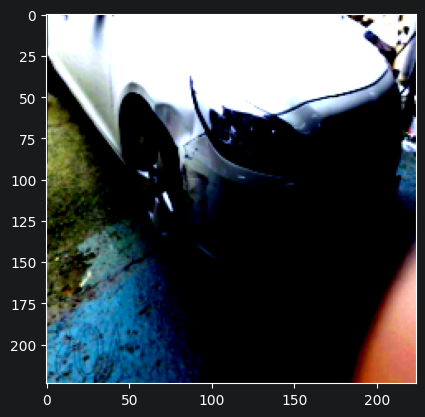

In [189]:
plt.imshow(images[0].cpu().permute(1,2,0))
plt.show()

## Model: Transfer Learning with Efficient Net V2-S (with hyperparameters updated from Optuna study)

In [190]:
def train_model(model, criterion, optimizer, train_loader, scheduler, val_loader, epochs=5):
    start = time.time()
    # Model Training:

    # Initialize best accuracy tracker before the training loop starts
    best_accuracy = 0.0
    # FIXED: Move scaler OUTSIDE the epoch loop to maintain state and fix the AssertionError.
    scaler = torch.amp.GradScaler('cuda')

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for batch_num, (images, labels) in enumerate(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            # Zero the parameter gradients
            optimizer.zero_grad()
            # Forward pass
            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, labels)
            # Backward pass
            scaler.scale(loss).backward()
            # Update the weights
            scaler.step(optimizer)
            scaler.update()

            if (batch_num+1) % 10 == 0:
                print(f"Batch: {batch_num+1}, Epoch: {epoch+1}, Loss: {loss.item():.2f}")

            running_loss += loss.item() * images.size(0)

        epoch_loss = running_loss/len(train_loader.dataset)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")

    # Model Evaluation:

        model.eval()
        total = 0.0
        correct = 0.0
        all_labels = []
        all_predictions = []
        val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                # OPTIMIZATION: Use autocast in validation too for speed/memory efficiency
                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
                all_labels.extend(labels.cpu().numpy())
                all_predictions.extend(predicted.cpu().numpy())

            val_accuracy = 100 * correct / total
            avg_val_loss = val_loss / len(val_loader.dataset)
            print(f"Validation Accuracy: {val_accuracy:.2f}%")

         # METHOD 1: Check if the current validation accuracy beats the historical best
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), '../assets/best_model_weights.pth')
            print(f"--> Saved new best model at epoch {epoch+1} with accuracy: {best_accuracy:.2f}%")

            # 2. FIX: Create a snapshot copy of the lists from this specific best epoch
            best_labels = all_labels.copy()
            best_predictions = all_predictions.copy()
        # FIXED: Call the scheduler step at the end of the epoch using validation loss
        scheduler.step(avg_val_loss)
    end = time.time()
    print(f'Execution time: {end - start} seconds')

    # Load the best weights back into memory before returning so the model is ready for testing/inference
    print(f"Loading best model weights from training (Best Accuracy: {best_accuracy:.2f}%)")
    model.load_state_dict(torch.load('../assets/best_model_weights.pth'))

    return best_labels, best_predictions

In [191]:
class CarClassifierEffNet(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.4):
        super().__init__()
        self.model = models.efficientnet_v2_s(weights='DEFAULT')
        # Freeze all layers except the final fully connected layer
        for param in self.model.parameters():
            param.requires_grad = False

        # Retrieve the in_features of the original classifier (which is a Sequential block)
        in_features = self.model.classifier[1].in_features
        # Unfreeze top 2 layers and fc layers
        for param in self.model.features[-2:].parameters():
            param.requires_grad = True
        # Replace the final fully connected layer
        self.model.classifier = nn.Sequential(
            nn.Linear(in_features, 256),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.model(x)

In [192]:
model = CarClassifierEffNet(num_classes=num_classes, dropout_rate=0.29).to(device)
model_eff = models.efficientnet_v2_s(weights='DEFAULT')
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW([
    {'params': model.model.features[-2:].parameters(), 'lr_bb': 4.6e-5},
    {'params': model.model.classifier.parameters(), 'lr_cl': 1.6e-4}
], weight_decay=3.5e-6)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.2)

labels, predictions = train_model(model=model, criterion=criterion, optimizer=optimizer, scheduler=scheduler, train_loader=train_loader, val_loader=val_loader, epochs=12)

Batch: 10, Epoch: 1, Loss: 1.14
Batch: 20, Epoch: 1, Loss: 0.99
Batch: 30, Epoch: 1, Loss: 0.86
Batch: 40, Epoch: 1, Loss: 0.68
Batch: 50, Epoch: 1, Loss: 0.93
Epoch [1/12], Loss: 0.9230
Validation Accuracy: 69.02%
--> Saved new best model at epoch 1 with accuracy: 69.02%
Batch: 10, Epoch: 2, Loss: 0.69
Batch: 20, Epoch: 2, Loss: 0.55
Batch: 30, Epoch: 2, Loss: 0.67
Batch: 40, Epoch: 2, Loss: 0.27
Batch: 50, Epoch: 2, Loss: 0.81
Epoch [2/12], Loss: 0.6699
Validation Accuracy: 71.04%
--> Saved new best model at epoch 2 with accuracy: 71.04%
Batch: 10, Epoch: 3, Loss: 0.28
Batch: 20, Epoch: 3, Loss: 0.53
Batch: 30, Epoch: 3, Loss: 0.53
Batch: 40, Epoch: 3, Loss: 0.30
Batch: 50, Epoch: 3, Loss: 0.96
Epoch [3/12], Loss: 0.5124
Validation Accuracy: 76.26%
--> Saved new best model at epoch 3 with accuracy: 76.26%
Batch: 10, Epoch: 4, Loss: 0.24
Batch: 20, Epoch: 4, Loss: 0.59
Batch: 30, Epoch: 4, Loss: 0.59
Batch: 40, Epoch: 4, Loss: 0.24
Batch: 50, Epoch: 4, Loss: 0.41
Epoch [4/12], Loss: 0

## Model Evaluation with Classification Report and Confusion Matrix

In [193]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from matplotlib import pyplot as plt

report = classification_report(labels, predictions)
print(report)

              precision    recall  f1-score   support

           0       0.89      0.91      0.90       142
           1       0.76      0.86      0.81        97
           2       0.96      0.86      0.91       126
           3       0.89      0.81      0.85        83
           4       0.79      0.81      0.80        84
           5       0.82      0.89      0.85        62

    accuracy                           0.86       594
   macro avg       0.85      0.85      0.85       594
weighted avg       0.86      0.86      0.86       594



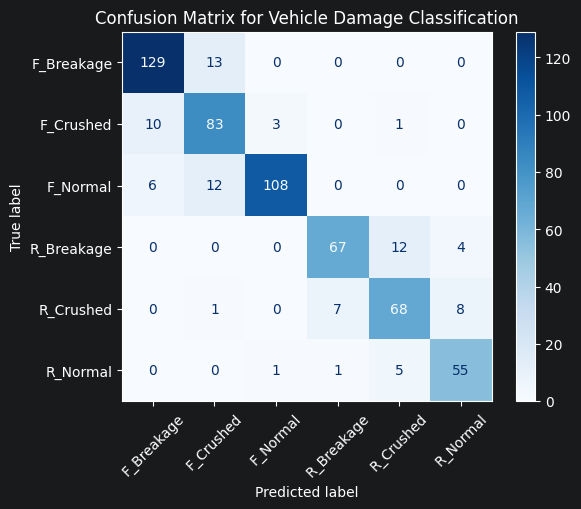

In [194]:
import numpy as np

class_names = dataset.classes

conf_matrix = confusion_matrix(labels, predictions, labels=np.arange(num_classes))
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
plt.title("Confusion Matrix for Vehicle Damage Classification")
plt.show()